# Cross-verification of the 2-D plate solvers against GMT `grdflexure` and gFlex

This notebook asks whether `SpectralPlate` and `FDPlate` (in [`../viscoelastic_plate.py`](../viscoelastic_plate.py)) give the same answers as two established, independently written flexure codes, on identical problems:

| reference code | what it solves | checks |
|---|---|---|
| **GMT `grdflexure`** (Wessel; GMT 6.5) | thin elastic or **Maxwell viscoelastic** plate over an inviscid fluid, by FFT, uniform thickness, with load histories | `SpectralPlate`: elastic response, time evolution through a fill–hold–drain history, the two-Poisson's-ratio option |
| **gFlex** (Wickert 2016; v1.3) | thin **elastic** plate by finite differences, with clamped, free or periodic edges and **spatially varying thickness** | `FDPlate` interior stencil and edges; the 1-D beam with varying thickness |

Two further tests have no external code to compare with, so they use an exact solution instead:

* a straight grounding line that is **not aligned with the grid**, so `FDPlate`'s mask is stair-stepped, against the exact clamped-beam solution;
* convergence as the grid is refined.

Every comparison quotes the largest difference over the domain, divided by the peak deflection.

In [1]:
import sys, time, subprocess
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import gflex

sys.path.insert(0, "..")
import plotstyle as ps
from viscoelastic_beam import IceShelf, ViscoelasticBeam, SECONDS_PER_DAY as DAY
from viscoelastic_plate import SpectralPlate, FDPlate
from gmt_flexure import grdflexure, gmt_version, GMT_G
ps.apply()
pd.set_option("display.precision", 3)
print("GMT", gmt_version(), "| gFlex", gflex.__version__ if hasattr(gflex, "__version__") else "1.3")

H, E, NU, ETA = 400.0, 1e9, 0.3, 1e14

def lake_grid(n, dx, depth=4.0, sx=1500.0, sy=900.0):
    x = (np.arange(n) - n / 2) * dx
    X, Y = np.meshgrid(x, x)
    d = depth * np.exp(-(X**2 / sx**2 + Y**2 / sy**2) / 2)
    return xr.DataArray(d, coords={"y": x, "x": x}, dims=("y", "x"))

def rel(a, b):
    return float(np.abs(np.asarray(a) - np.asarray(b)).max() / np.abs(np.asarray(b)).max())

results = []          # rows of the summary table
print(f"flexural length for H = {H:.0f} m: {IceShelf(H=H, E=E, nu=NU).ell:.0f} m")

GMT 6.5.0 | gFlex 1.3.0
flexural length for H = 400 m: 873 m


## A. GMT `grdflexure` against `SpectralPlate`

**Mapping our problem onto `grdflexure`.** With its moat infill equal to the load density, `grdflexure` solves $D\nabla^4 w + (\rho_m-\rho_l)g\,w = (\rho_l-\rho_w)g\,h$ for a load "topography" $h$. Setting $\rho_l = 2000$, $\rho_m = 2000+\rho_{sw}$, $\rho_w = 2000-1000$ and $h$ = lake depth reproduces our $D\nabla^4 w + \rho_{sw}g\,w = \rho_w g\,d$ exactly. (Values below 10 are read as g/cm³, so dummy densities must stay large.)

**Its Maxwell model** (`-M`) relaxes each Fourier mode as $1 - [1-\Phi_e]\,e^{-\Phi_e t/t_m}$, with $\Phi_e = 1/(1+(k\ell)^4)$. That is our plate with a single relaxation time ($\nu_v = \nu$) and $t_m = \tau = 4\eta(1-\nu^2)/E$.

**Gravity.** `grdflexure` uses its own value of $g$. With $g$ = 9.806199203 m s⁻², agreement is at float32 round-off; with 9.81 it is about $10^{-4}$.

### A1. The density mapping: a very broad load must float isostatically

In [2]:
n, dx = 256, 500.0
broad = lake_grid(n, dx, depth=1.0, sx=20e3, sy=20e3)
wg = grdflexure([(0.0, broad)], [0.0], H=H, E=E, nu=NU)[0]
centre = float(wg.sel(x=0, y=0))
print(f"centre deflection {centre:.5f} m under 1 m of water; floating balance gives rho_w/rho_sw = {1000/1028:.5f}")

centre deflection 0.97273 m under 1 m of water; floating balance gives rho_w/rho_sw = 0.97276


### A2. Elastic response to a lake

The lake is 4 m deep and roughly 3 km by 2 km, on 400 m ice, on a 25.6 km periodic grid at 100 m. `grdflexure` runs with `-Nf+n+l`: it transforms the grid as given, with no extension, taper or detrending, which matches `SpectralPlate`'s periodic domain.

,centre_GMT,centre_ours,max_diff_over_peak
g,,,
9.810,2.214,2.214,9.232e-05
9.806,2.214,2.214,2.557e-07


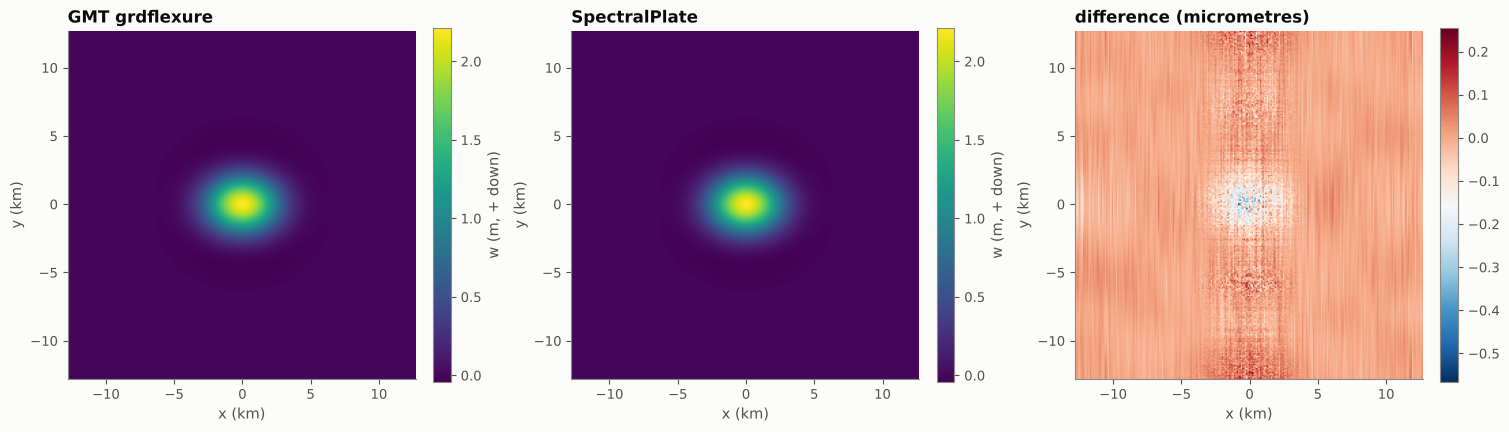

In [3]:
n, dx = 256, 100.0
lake = lake_grid(n, dx)
wg = grdflexure([(0.0, lake)], [0.0], H=H, E=E, nu=NU)[0].values
rows = []
for g in (9.81, GMT_G):
    s = IceShelf(H=H, E=E, nu=NU, nu_v=NU, g=g)
    w = SpectralPlate(n, n, dx, s).elastic(s.lake_load(lake.values))
    rows.append(dict(g=g, centre_GMT=wg[n // 2, n // 2], centre_ours=w[n // 2, n // 2], max_diff_over_peak=rel(wg, w)))
    if g == GMT_G:
        w_el = w
display(pd.DataFrame(rows).set_index("g"))
results.append(dict(case="A2 elastic lake, uniform H (FFT)", reference="GMT grdflexure",
                    ours="SpectralPlate", max_diff_over_peak=rel(wg, w_el)))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
ext = [lake.x.min() / 1e3, lake.x.max() / 1e3, lake.y.min() / 1e3, lake.y.max() / 1e3]
for a, f, t in [(ax[0], wg, "GMT grdflexure"), (ax[1], w_el, "SpectralPlate")]:
    im = a.imshow(f, extent=ext, origin="lower", cmap="viridis"); a.set_title(t); fig.colorbar(im, ax=a, label="w (m, + down)")
im = ax[2].imshow(1e6 * (wg - w_el), extent=ext, origin="lower", cmap="RdBu_r")
ax[2].set_title("difference (micrometres)"); fig.colorbar(im, ax=ax[2])
for a in ax: a.set(xlabel="x (km)", ylabel="y (km)"); a.grid(False)

### A3. Viscoelastic response through a fill–hold–drain history

The lake fills in 10 daily steps of 10% each (days 0.5 to 9.5), holds, drains instantly at day 20.5, and is followed to day 40. The steps fall between the daily output times on purpose: at an output time exactly equal to a step time, grdflexure includes or excludes the step depending on round-off in the age. The viscosity is $\eta = 10^{14}$ Pa s, which gives $\tau$ = 4.2 days. Both codes see the same staircase of load increments:

* `grdflexure` superposes the response to each increment;
* `SpectralPlate` integrates each Fourier mode exactly in time, with an elastic jump at every step.

GMT run: 1.6 s;  largest difference over the history / peak: 2.1e-07
two-Poisson's-ratio default vs GMT's single-time model: up to 0.3% of the peak (a model difference, not an error)


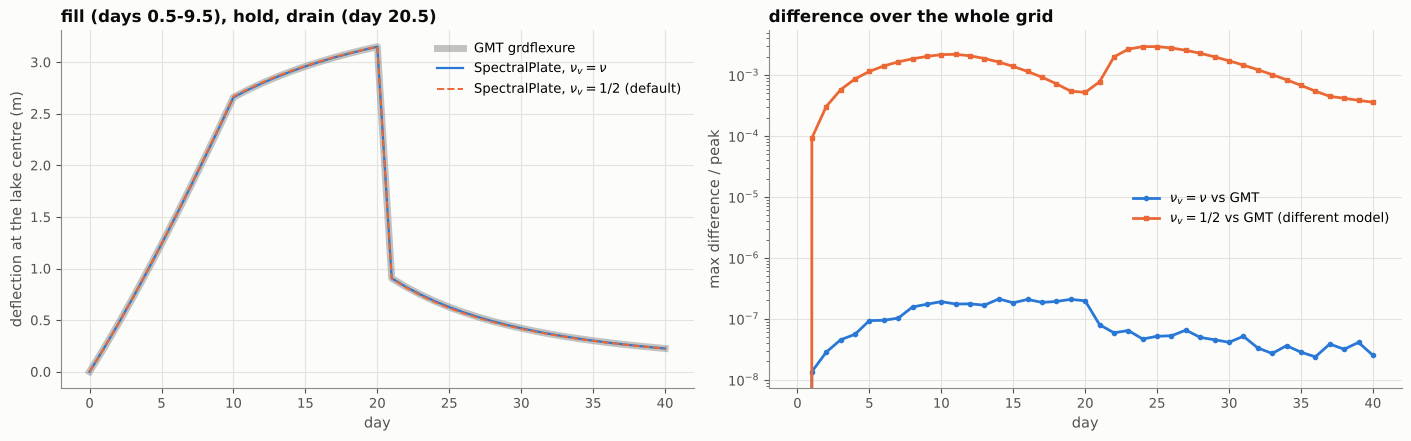

In [4]:
shelf1 = IceShelf(H=H, E=E, nu=NU, nu_v=NU, eta=ETA, g=GMT_G)
steps = [((t + 0.5) * DAY, 0.1) for t in range(10)] + [(20.5 * DAY, -1.0)]
out = np.arange(0, 41) * DAY
t0 = time.perf_counter()
wg_t = grdflexure([(t, f * lake) for t, f in steps], out, H=H, E=E, nu=NU, tm=shelf1.tau)
t_gmt = time.perf_counter() - t0

def staircase(steps, out):
    tt, ff, cum = [0.0], [0.0], 0.0
    for t in sorted(set(out) | {ts for ts, _ in steps}):
        f = sum(f for ts, f in steps if ts == t)
        tt.append(t); ff.append(cum)
        if f:
            cum += f; tt.append(t); ff.append(cum)
    return np.array(tt), np.array(ff)

def ours_history(shelf, steps, out):
    tt, ff = staircase(steps, out)
    r = SpectralPlate(n, n, dx, shelf).run(tt, (shelf.lake_load(lake.values), ff), store_mu=False, stresses=False)
    idx = [int(np.flatnonzero(np.isclose(r.time.values, t)).max()) for t in out]   # after any jump
    return r.w.values[idx]

wo_t = ours_history(shelf1, steps, out)
err_t = np.abs(wg_t.values - wo_t).max(axis=(1, 2)) / np.abs(wo_t).max()
print(f"GMT run: {t_gmt:.1f} s;  largest difference over the history / peak: {err_t.max():.1e}")
results.append(dict(case="A3 viscoelastic fill-hold-drain, uniform H (FFT)", reference="GMT grdflexure -M",
                    ours="SpectralPlate (nu_v = nu)", max_diff_over_peak=float(err_t.max())))

shelf2 = IceShelf(H=H, E=E, nu=NU, nu_v=0.5, eta=ETA, g=GMT_G)      # our default: two relaxation times
wo2_t = ours_history(shelf2, steps, out)

days = out / DAY
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3), constrained_layout=True)
ax[0].plot(days, wg_t.values[:, n // 2, n // 2], color=ps.MUTED, lw=5, alpha=0.5, label="GMT grdflexure")
ax[0].plot(days, wo_t[:, n // 2, n // 2], color=ps.VISCO, lw=1.6, label=r"SpectralPlate, $\nu_v=\nu$")
ax[0].plot(days, wo2_t[:, n // 2, n // 2], color=ps.ELASTIC, lw=1.4, ls="--", label=r"SpectralPlate, $\nu_v=1/2$ (default)")
ax[0].set(xlabel="day", ylabel="deflection at the lake centre (m)", title="fill (days 0.5-9.5), hold, drain (day 20.5)")
ax[0].legend()
ax[1].semilogy(days, err_t, "o-", color=ps.VISCO, ms=3, label=r"$\nu_v=\nu$ vs GMT")
ax[1].semilogy(days, np.abs(wg_t.values - wo2_t).max(axis=(1, 2)) / np.abs(wo2_t).max(), "s-", color=ps.ELASTIC, ms=3,
               label=r"$\nu_v=1/2$ vs GMT (different model)")
ax[1].set(xlabel="day", ylabel="max difference / peak", title="difference over the whole grid")
ax[1].legend();
print(f"two-Poisson's-ratio default vs GMT's single-time model: up to "
      f"{np.abs(wg_t.values - wo2_t).max() / np.abs(wo2_t).max():.1%} of the peak (a model difference, not an error)")

## B. gFlex against `FDPlate` and the 1-D beam

gFlex solves the elastic plate with the same 13-point finite-difference biharmonic stencil, written independently, with variable rigidity after van Wees & Cloetingh (1994). Settings: `rho_m` = 1028, `rho_fill` = 0, and the load `qs` = ρ_w g d, in Pa.

### B1. Periodic edges, and convergence to the FFT solution

In [5]:
def gflex_w(q, dx, bc, Te=H, g=9.81, bc_ns=None):
    f = gflex.F2D(); f.Quiet = True; f.Method = "FD"; f.PlateSolutionType = "vWC1994"; f.Solver = "direct"
    f.g = g; f.E = E; f.nu = NU; f.rho_m = 1028.0; f.rho_fill = 0.0
    f.Te = Te; f.qs = np.array(q, float); f.dx = f.dy = dx
    f.BC_W = f.BC_E = bc; f.BC_N = f.BC_S = bc_ns or bc
    f.initialize(); f.run(); f.finalize()
    return -f.w                                    # gFlex: negative down

s = IceShelf(H=H, E=E, nu=NU, nu_v=NU)
rows = []
for dxi in (200.0, 100.0, 50.0, 25.0):
    ni = int(12800 / dxi)
    li = lake_grid(ni, dxi)
    q = s.lake_load(li.values)
    wgf = gflex_w(q, dxi, "Periodic")
    wfd, _ = FDPlate(ni, ni, dxi, s, edges="periodic").elastic(q)
    wsp = SpectralPlate(ni, ni, dxi, s).elastic(q)
    rows.append(dict(dx=dxi, dx_over_ell=dxi / float(s.ell), gflex_vs_FDPlate=rel(wgf, wfd),
                     FDPlate_vs_spectral=rel(wfd, wsp)))
b1 = pd.DataFrame(rows).set_index("dx")
b1["rate"] = np.r_[np.nan, np.log2(b1.FDPlate_vs_spectral.values[:-1] / b1.FDPlate_vs_spectral.values[1:])]
display(b1)
results.append(dict(case="B1 elastic lake, periodic (FD stencil)", reference="gFlex",
                    ours="FDPlate", max_diff_over_peak=float(b1.gflex_vs_FDPlate.max())))
results.append(dict(case="B1 FD truncation at dx = ell/9", reference="SpectralPlate (exact in space)",
                    ours="FDPlate", max_diff_over_peak=float(b1.FDPlate_vs_spectral.loc[100.0])))

,dx_over_ell,gflex_vs_FDPlate,FDPlate_vs_spectral,rate
dx,,,,
200.0,0.229,1.258e-12,1.960e-03,NaN
100.0,0.115,2.244e-11,4.884e-04,2.005
50.0,0.057,2.935e-10,1.220e-04,2.001
25.0,0.029,5.262e-09,3.049e-05,2.000


### B2. Clamped edges

The two codes place a clamped edge slightly differently. `FDPlate` holds the edge nodes at $w = 0$ and reflects across them. gFlex applies its boundary through ghost nodes. So they agree only up to discretisation error, and the difference should shrink as the grid is refined.

In [6]:
rows = []
for dxi in (200.0, 100.0, 50.0):
    ni = int(12800 / dxi)
    q = s.lake_load(lake_grid(ni, dxi).values)
    wgf = gflex_w(q, dxi, "0Displacement0Slope")
    wfd, _ = FDPlate(ni, ni, dxi, s, edges="clamped").elastic(q)
    rows.append(dict(dx=dxi, gflex_vs_FDPlate=rel(wgf, wfd)))
b2 = pd.DataFrame(rows).set_index("dx")
b2["rate"] = np.r_[np.nan, np.log2(b2.gflex_vs_FDPlate.values[:-1] / b2.gflex_vs_FDPlate.values[1:])]
display(b2)
results.append(dict(case="B2 elastic lake, clamped box edges, dx = 100 m", reference="gFlex",
                    ours="FDPlate", max_diff_over_peak=float(b2.gflex_vs_FDPlate.loc[100.0])))

,gflex_vs_FDPlate,rate
dx,,
200.0,3.060e-03,NaN
100.0,1.568e-03,0.965
50.0,7.900e-04,0.989


### B3. A grounding line not aligned with the grid

No external code can hold an irregular interior region fixed. So instead we take a straight grounding line with a lake 2.5 km out on the shelf, the same at every point along the line. That is a plane-strain problem, whose exact answer is the 1-D clamped beam, computed with `ViscoelasticBeam` at 1 m resolution.

`FDPlate` sees the grounding line as a mask of fixed nodes, which becomes a staircase when the line is rotated. Two ways of drawing the mask are tried:

* **"nodes inside"** fixes nodes with $s < 0$ (the obvious choice);
* **"nodes within half a cell"** also fixes nodes with $0 \le s < \Delta x/2$, so that a node lying on the grounding line is held.

Here $s$ is the distance from the grounding line, positive on the shelf. The errors are compared within 3 km of the domain's centre line and up to 8 km out on the shelf.

angle  0, nodes inside             : convergence rates [0.86 0.93]
angle  0, nodes within half a cell : convergence rates [0.9  0.95]
angle 30, nodes inside             : convergence rates [1.01 0.97]
angle 30, nodes within half a cell : convergence rates [1.25 0.98]


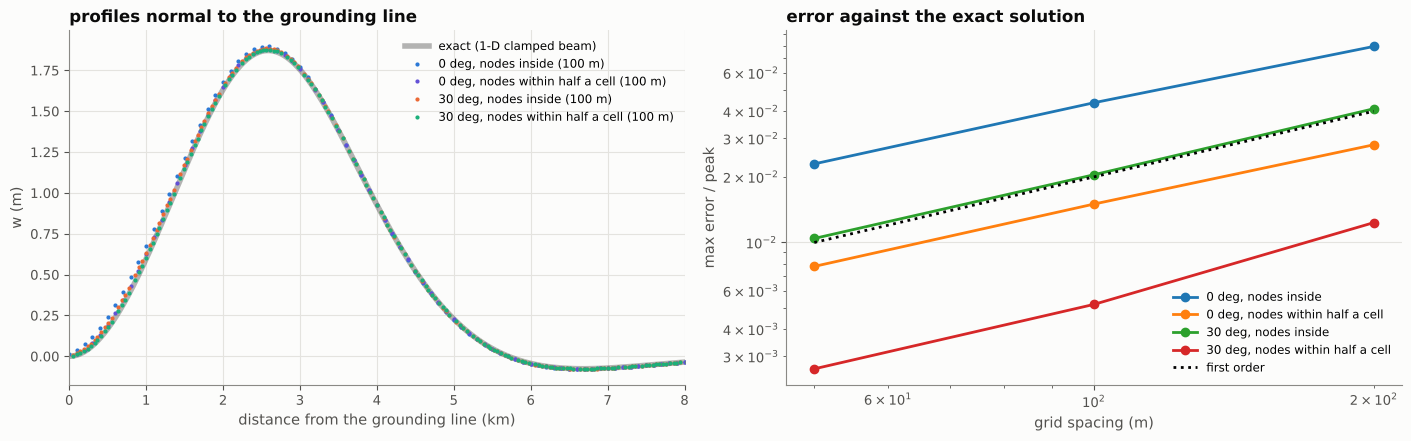

In [7]:
qs_fn = lambda sn: s.lake_load(4.0 * np.exp(-((sn - 2500.0) / 800.0) ** 2))
xb = np.linspace(0, 30e3, 30001)
wb, _ = ViscoelasticBeam(xb, s, "clamped", "free").elastic(qs_fn(xb))
L = 20e3
rows, profiles = [], {}
for theta in (0.0, 30.0):
    th = np.radians(theta)
    for rule, shift in [("nodes inside", 0.0), ("nodes within half a cell", 0.5)]:
        for dxi in (200.0, 100.0, 50.0):
            ni = int(L / dxi); x = (np.arange(ni) - ni / 2) * dxi; X, Y = np.meshgrid(x, x)
            sn = X * np.cos(th) + Y * np.sin(th) + 4000.0
            fixed = sn < shift * dxi
            w, _ = FDPlate(ni, ni, dxi, s, fixed=fixed).elastic(np.where(fixed, 0.0, qs_fn(sn)))
            along = -X * np.sin(th) + Y * np.cos(th)
            m = (~fixed) & (np.abs(along) < 3000) & (sn < 8000) & (sn > 0)
            rows.append(dict(angle=theta, mask=rule, dx=dxi, error=float(np.abs(w[m] - np.interp(sn[m], xb, wb)).max() / wb.max())))
            if dxi == 100.0:
                c = np.abs(along) < dxi
                profiles[(theta, rule)] = (sn[c & ~fixed], w[c & ~fixed])
b3 = pd.DataFrame(rows)
b3["error x ell/dx"] = b3.error * float(s.ell) / b3.dx
display(b3.pivot_table(index=["angle", "mask"], columns="dx", values="error").style.format("{:.2%}"))
for (a_, r_), g_ in b3.groupby(["angle", "mask"]):
    e = g_.sort_values("dx", ascending=False).error.values
    print(f"angle {a_:2.0f}, {r_:25s}: convergence rates {np.round(np.log2(e[:-1] / e[1:]), 2)}")
results.append(dict(case="B3 grounding line at 30 deg, dx = 100 m, mask 'nodes inside'", reference="exact clamped beam",
                    ours="FDPlate", max_diff_over_peak=float(b3.query("angle == 30 and mask == 'nodes inside' and dx == 100").error.iloc[0])))
results.append(dict(case="B3 grounding line at 30 deg, dx = 100 m, mask 'within half a cell'", reference="exact clamped beam",
                    ours="FDPlate", max_diff_over_peak=float(b3.query("angle == 30 and mask == 'nodes within half a cell' and dx == 100").error.iloc[0])))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.3), constrained_layout=True)
ax[0].plot(xb / 1e3, wb, color=ps.INK, lw=4, alpha=0.3, label="exact (1-D clamped beam)")
for ((theta, rule), (sn_, w_)), c in zip(profiles.items(), [ps.VISCO, ps.ACCENT, ps.ELASTIC, ps.ISO]):
    o = np.argsort(sn_)
    ax[0].plot(sn_[o] / 1e3, w_[o], ".", ms=4, color=c, label=f"{theta:.0f} deg, {rule} (100 m)")
ax[0].set(xlim=(0, 8), xlabel="distance from the grounding line (km)", ylabel="w (m)", title="profiles normal to the grounding line")
ax[0].legend(fontsize=8.5)
for (theta, rule), g_ in b3.groupby(["angle", "mask"]):
    ax[1].loglog(g_.dx, g_.error, "o-", label=f"{theta:.0f} deg, {rule}")
ax[1].loglog([50, 200], [0.01, 0.04], "k:", label="first order")
ax[1].set(xlabel="grid spacing (m)", ylabel="max error / peak", title="error against the exact solution")
ax[1].legend(fontsize=8.5);

### B4. Spatially varying thickness

Thickness rises linearly from 200 to 600 m across a 30 km strip, with both ends clamped and a lake at 12 km. gFlex solves it in 2-D, uniform along y and periodic in y. That is plane strain, so it must equal our 1-D `ViscoelasticBeam` with an array `H`. (`FDPlate` and `SpectralPlate` need a uniform thickness.)

In [8]:
rows = []
for dxi in (200.0, 100.0, 50.0):
    x = np.linspace(0, 30e3, int(30e3 / dxi) + 1)
    Hx = 200.0 + 400.0 * x / 30e3
    sv = IceShelf(H=Hx, E=E, nu=NU, nu_v=NU)
    q = sv.lake_load(4.0 * np.exp(-((x - 12e3) / 1500.0) ** 2))
    wbx, _ = ViscoelasticBeam(x, sv, "clamped", "clamped").elastic(q)
    wgx = gflex_w(np.tile(q, (8, 1)), dxi, "0Displacement0Slope", Te=np.tile(Hx, (8, 1)), bc_ns="Periodic")[4]
    rows.append(dict(dx=dxi, peak_beam=wbx.max(), peak_gflex=wgx.max(), max_diff_over_peak=rel(wgx, wbx)))
b4 = pd.DataFrame(rows).set_index("dx")
display(b4)
results.append(dict(case="B4 H = 200-600 m, plane strain, dx = 100 m", reference="gFlex (2-D)",
                    ours="ViscoelasticBeam (1-D)", max_diff_over_peak=float(b4.max_diff_over_peak.loc[100.0])))

,peak_beam,peak_gflex,max_diff_over_peak
dx,,,
200.0,3.052,3.052,1.918e-05
100.0,3.049,3.049,4.816e-06
50.0,3.049,3.049,1.204e-06


## Summary

In [9]:
pd.DataFrame(results).style.format({"max_diff_over_peak": "{:.1e}"}).hide(axis="index")

case,reference,ours,max_diff_over_peak
"A2 elastic lake, uniform H (FFT)",GMT grdflexure,SpectralPlate,2.6e-07
"A3 viscoelastic fill-hold-drain, uniform H (FFT)",GMT grdflexure -M,SpectralPlate (nu_v = nu),2.1e-07
"B1 elastic lake, periodic (FD stencil)",gFlex,FDPlate,5.3e-09
B1 FD truncation at dx = ell/9,SpectralPlate (exact in space),FDPlate,4.9e-04
"B2 elastic lake, clamped box edges, dx = 100 m",gFlex,FDPlate,1.6e-03
"B3 grounding line at 30 deg, dx = 100 m, mask 'nodes inside'",exact clamped beam,FDPlate,2.0e-02
"B3 grounding line at 30 deg, dx = 100 m, mask 'within half a cell'",exact clamped beam,FDPlate,5.2e-03
"B4 H = 200-600 m, plane strain, dx = 100 m",gFlex (2-D),ViscoelasticBeam (1-D),4.8e-06


**What is verified, and how well** (differences are the largest over the grid, as a fraction of the peak deflection):

* **`SpectralPlate` reproduces GMT `grdflexure` to float32 round-off,** about $10^{-7}$. This holds elastically and through a whole viscoelastic fill–hold–drain history, once both use the same $g$. The FFT solution, the exact-in-time Maxwell integration, and our handling of load histories are all independently confirmed.
* **Our default two-Poisson's-ratio model ($\nu_v = 1/2$)** has no external counterpart. It differs from the single-relaxation-time model by up to 0.3% of the deflection in this experiment. It is verified only internally, by the moment-law tests in `tests/`.
* **`FDPlate`'s interior is identical to gFlex,** to round-off ($10^{-11}$–$10^{-9}$). Both converge at second order to the exact FFT solution: the error is $5\times10^{-4}$ at $\Delta x = \ell/9$ and $2\times10^{-3}$ at $\ell/4.4$.
* **Clamped box edges** are implemented slightly differently in the two codes, and the difference shrinks at first order: 0.16% at 100 m.
* **Grounding lines are the dominant numerical error.** A clamp built from a mask of fixed nodes is first order.
  * The error is about $0.4\,\Delta x/\ell$ when the grounding line runs along the grid and $0.2\,\Delta x/\ell$ at 30°, with the obvious mask (fix nodes with $s < 0$).
  * Fixing also the nodes within half a cell outside, $s < \Delta x/2$, cuts the error by a factor of 2–4 at the same cost.
  * With the 128 m plate grid and $\ell$ = 873 m used in the routing notebooks, that means about 2–6%. That matches the grid sensitivity seen near the grounding line in `lake_drainage_flexure.ipynb`.
* **Varying thickness** (plane strain): the 1-D beam with $H(x)$ agrees with gFlex's 2-D variable-rigidity solver to $5\times10^{-6}$ at 100 m, converging at second order.

**What this means for research use**

* **Uniform-thickness viscoelastic problems** on a periodic domain (`SpectralPlate`) can be trusted to round-off for the model as written. The remaining questions are about physics and parameters, not numerics.
* **With `FDPlate`,** use $\Delta x \lesssim \ell/5$ in the interior, where truncation error is below 0.2%.
* **Near grounding lines,** either refine ($\Delta x \lesssim \ell/20$ for errors around 1–2%), or use the half-cell mask rule. In any case quote the grounding-line error, which is typically smaller than the uncertainty in the grounding-line position itself (the 500 m mask).
* **Still not verified externally,** because no open code exists for these: two-dimensional viscoelastic flexure with varying thickness, viscoelastic flexure combined with a grounding line, and free calving-front edges in 2-D.

Reproduce with GMT ≥ 6.5 on the path and `pip install gflex` (v1.3.0 here); see [`README.md`](README.md). The coarse versions of these checks run in `tests/test_cross_verification.py`.